In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
# The code lives in the msm/ folder. Checks: `python -m unittest -v` in this folder.
%load_ext autoreload
%autoreload 2
import msm

# Islands

In [2]:
# ── Islands (edit here) ──────────────────────────────────────────────────────
# Every island has:   "structures", and your collection by size in two parts:
#                     "trios":       groups of 3 identical monsters, kept side by side (T1, T2, ... in Excel)
#                     "individuals": every other monster
#                     (e.g. 14 trios of 2x2 and 10 other 2x2s: "trios": {2: 14}, "individuals": {2: 10})
# and is either
#   income mode:  "catalog" (extras the solver may add) + "beds" (extras use exactly this many)
#   fill mode:    no catalog -> as many fill squares as fit ("fill": 2 = 2x2, 3 = 3x3)
# Optional:  "csv" (default "Original.csv"; e.g. "Platformless.csv"),
#            "excel" (default "<island>.xlsx"),
#            "flip_up": True if the yellow 'in-game up' arrow points the wrong way,
#            "locked": pieces pinned to a cell (the piece's top-left cell, as in the Excel file):
#                [{"what": "Nursery", "at": "N3"},   ("structure" + "size" also works when only one type has that size)
#                 {"what": "Wubbox", "at": "R10"},
#                 {"what": "collection", "size": 2, "at": "J20"}]
#
# Name structures: shapes are mirrored by size, then the same type is put opposite
# itself wherever possible (bakery with bakery):
#   STRUCTURES = [("Castle", 4, 1), ("Breeding", 4, 1), ("Nursery", 4, 1), ("Bakery", 3, 2), ...]

STRUCTURES = [("Nursery", 4, 2), ("Storage", 4, 1), 
              ("Bakery", 3, 5), ("Mine", 3, 1), ("UT", 3, 1), 
              ("WT", 1, 10), ("ColossEye", 1, 1)]
MSTRUCTURES = [("Nursery", 4, 2), ("Storage", 4, 1), 
              ("Bakery", 3, 5), ("Mine", 3, 1), ("UT", 3, 1), 
              ("WT", 1, 10)]
ESSENTIALS = [("Nursery", 4, 2), ("Storage", 4, 1), 
              ("Mine", 3, 1), ("UT", 3, 1), 
              ("WT", 1, 10)]

NATNFIR = [
    # income = per monster (any unit, same for all)   beds = beds one takes (default 1)
    # optional: "min" / "max" how many,  "back": False to let it sit anywhere (default: at the back)
    {"name": "Wubbox",    "size": 4, "income": 750855, "beds": 1},
    {"name": "Werdo",     "size": 2, "income": 408799, "beds": 1},
    {"name": "Dipster",   "size": 1, "income": 18771,  "beds": 0, "max": 54},
    {"name": "E Dipster", "size": 1, "income": 23483,  "beds": 0, "max": 28},
    {"name": "R Dipster", "size": 2, "income": 37562,  "beds": 0, "max": 7 },
]

VEV = [
    {"name": "Veveine",    "size": 2, "income": 87645, "beds": 1},
]

ETHEREAL = [
    {"name": "Monculus",  "size": 2, "income": 696, "beds": 1},
    {"name": "Dipster",   "size": 1, "income": 58,  "beds": 0, "max": 54},
    {"name": "E Dipster", "size": 1, "income": 73,  "beds": 0, "max": 28},
]

WORKSHOP = [
    {"name": "Teeter-Tauter", "size": 2, "income": 580, "beds": 15},
]

ISLANDS = {
    "Plant":     {"structures": STRUCTURES,  "trios": {3: 1, 2: 14, 1: 3}, "individuals": {4: 3,       2: 3+7   , 1: 14}, "beds": 36, "catalog": NATNFIR },
    "MPlant":    {"structures": MSTRUCTURES, "trios": {3: 1, 2: 14, 1: 3}, "individuals": {4: 3,       2: 3+7   , 1: 14}, "beds": 36, "catalog": NATNFIR },
    "Cold":      {"structures": STRUCTURES,  "trios": {3: 3, 2: 12, 1: 3}, "individuals": {4: 3,       2: 3+7   , 1: 14}, "beds": 36, "catalog": NATNFIR },
    "MCold":     {"structures": MSTRUCTURES, "trios": {3: 3, 2: 12, 1: 3}, "individuals": {4: 3,       2: 3+7   , 1: 14}, "beds": 36, "catalog": NATNFIR },
    "Air":       {"structures": STRUCTURES,  "trios": {3: 2, 2: 16, 1: 1}, "individuals": {4: 3,       2: 3+7   , 1: 14}, "beds": 28, "catalog": NATNFIR },
    "MAir":      {"structures": MSTRUCTURES, "trios": {3: 2, 2: 16, 1: 1}, "individuals": {4: 3,       2: 3+7   , 1: 14}, "beds": 28, "catalog": NATNFIR },
    "Water":     {"structures": STRUCTURES,  "trios": {3: 4, 2: 12, 1: 2}, "individuals": {4: 3, 3: 1, 2: 2+7   , 1: 14}, "beds": 34, "catalog": NATNFIR },
    "MWater":    {"structures": MSTRUCTURES, "trios": {3: 4, 2: 12, 1: 2}, "individuals": {4: 3, 3: 1, 2: 2+7   , 1: 14}, "beds": 34, "catalog": NATNFIR },
    "Earth":     {"structures": STRUCTURES,  "trios": {3: 1, 2: 13, 1: 4}, "individuals": {4: 3,       2: 2+7   , 1: 14}, "beds": 38, "catalog": NATNFIR },
    "MEarth":    {"structures": MSTRUCTURES, "trios": {3: 1, 2: 13, 1: 4}, "individuals": {4: 3,       2: 2+7   , 1: 14}, "beds": 38, "catalog": NATNFIR },
    "Shugabush": {"structures": MSTRUCTURES, "trios": {3: 2, 2: 4 , 1: 2}, "individuals": {            2: 8            }, "beds": 19, "catalog": VEV     },
    # "Bbli$zard": {"structures": MSTRUCTURES, "trios": {3: 2, 2: 5       }, "individuals": {            2: 8            }, "beds":   , "catalog":        , "csv": "Dotless.csv"},
    "Ethereal":  {"structures": ESSENTIALS,  "trios": {3: 1, 2: 15      }, "individuals": {4: 3,       2: 7     , 1: 14},             "catalog": ETHEREAL},
    # "Workshop":  {"structures": ESSENTIALS,  "trios": {3: 6, 2: 9       }, "individuals": {4: 3                        }, "beds":   , "catalog": WORKSHOP},
    # "Haven":     {"structures": STRUCTURES,  "trios": {3: 2, 2: 14, 1: 2}, "individuals": {4: 3,       2: 2+7   , 1: 14}, "beds": 39, "catalog": NATNFIR, "csv": "Haven.csv"},
    # "Crystal":   {"structures": STRUCTURES,  "trios": {3: 3, 2: 10      }, "individuals": {                            }, "csv": "Crystal.csv"},
    # "Light":     {"structures": STRUCTURES,  "trios": {3: 4, 2: 14, 1: 3}, "individuals": {4: 1,       2: 7+24+7, 1: 14}, "beds": 36, "catalog": NATNFIR},
}

# Settings

In [3]:
# ── Settings ─────────────────────────────────────────────────────────────────
ISLAND           = "Plant"  # the island "Run one island" solves
RUN_TO_OPTIMAL   = True     # True = income/fill and symmetry run until proven best (no time limit)
MAX_SOLVE_SECS   = 60       # total time limit, only used when RUN_TO_OPTIMAL = False
ARRANGE_MAX_SECS = 160      # cap on the last tidy-up step only; never changes income/fill/symmetry
SYMMETRY         = True     # mirror structures across the in-game axis
WORKERS          = None     # None = this computer's cores, picked automatically; or a number used for every step, e.g. 4 to keep the PC free
PARALLEL         = 1        # "Run all": islands solved at once; None = as many as the cores allow, 1 = one at a time (tidiest)
TRIO_GAP         = 1        # trios: tiles allowed between the 3 (0 = must touch; touching is still preferred, more = looser trios)
LOG              = True     # print each step as it finishes

OPTIONS = dict(time_limit=None if RUN_TO_OPTIMAL else MAX_SOLVE_SECS, arrange_time_limit=ARRANGE_MAX_SECS,
               symmetry=SYMMETRY, workers=WORKERS, trio_gap=TRIO_GAP, log=LOG)

# Run one island

[10:15:35] Plant: 737 open tiles, mirror axis anti c=35 (734/737 tiles mirror), 8 workers (16 for packing)
[10:15:38] Plant: income 19,374,839 (bound 19,374,839) {'Wubbox': 13, 'Werdo': 23, 'Dipster': 0, 'E Dipster': 9, 'R Dipster': 0} | 3.4s
[10:15:57] Plant: every structure can be mirrored (back-band spots) | 18.4s
[10:15:57] Plant: mirrored 21/21 (bound 21) | 18.5s
[10:16:11] Plant: arranged (0.1% from the solver's bound) | 13.7s
[10:16:11] Plant: trios kept together: 4x4 1/1, 3x3 0/1, 2x2 14/14, 1x1 3/3
Island                 Plant
Grid                   Original.csv
Mode                   income
Income                 19374839
Best possible income   19374839
Income proven best     yes
Extra: Wubbox          13
Extra: Werdo           23
Extra: Dipster         0
Extra: E Dipster       9
Extra: R Dipster       0
Beds used              36/36
Mirrored structures    21/21
Symmetry proven best   yes
Same type opposite     19/21
Arrangement            0.1% from the solver's bound (cosmeti

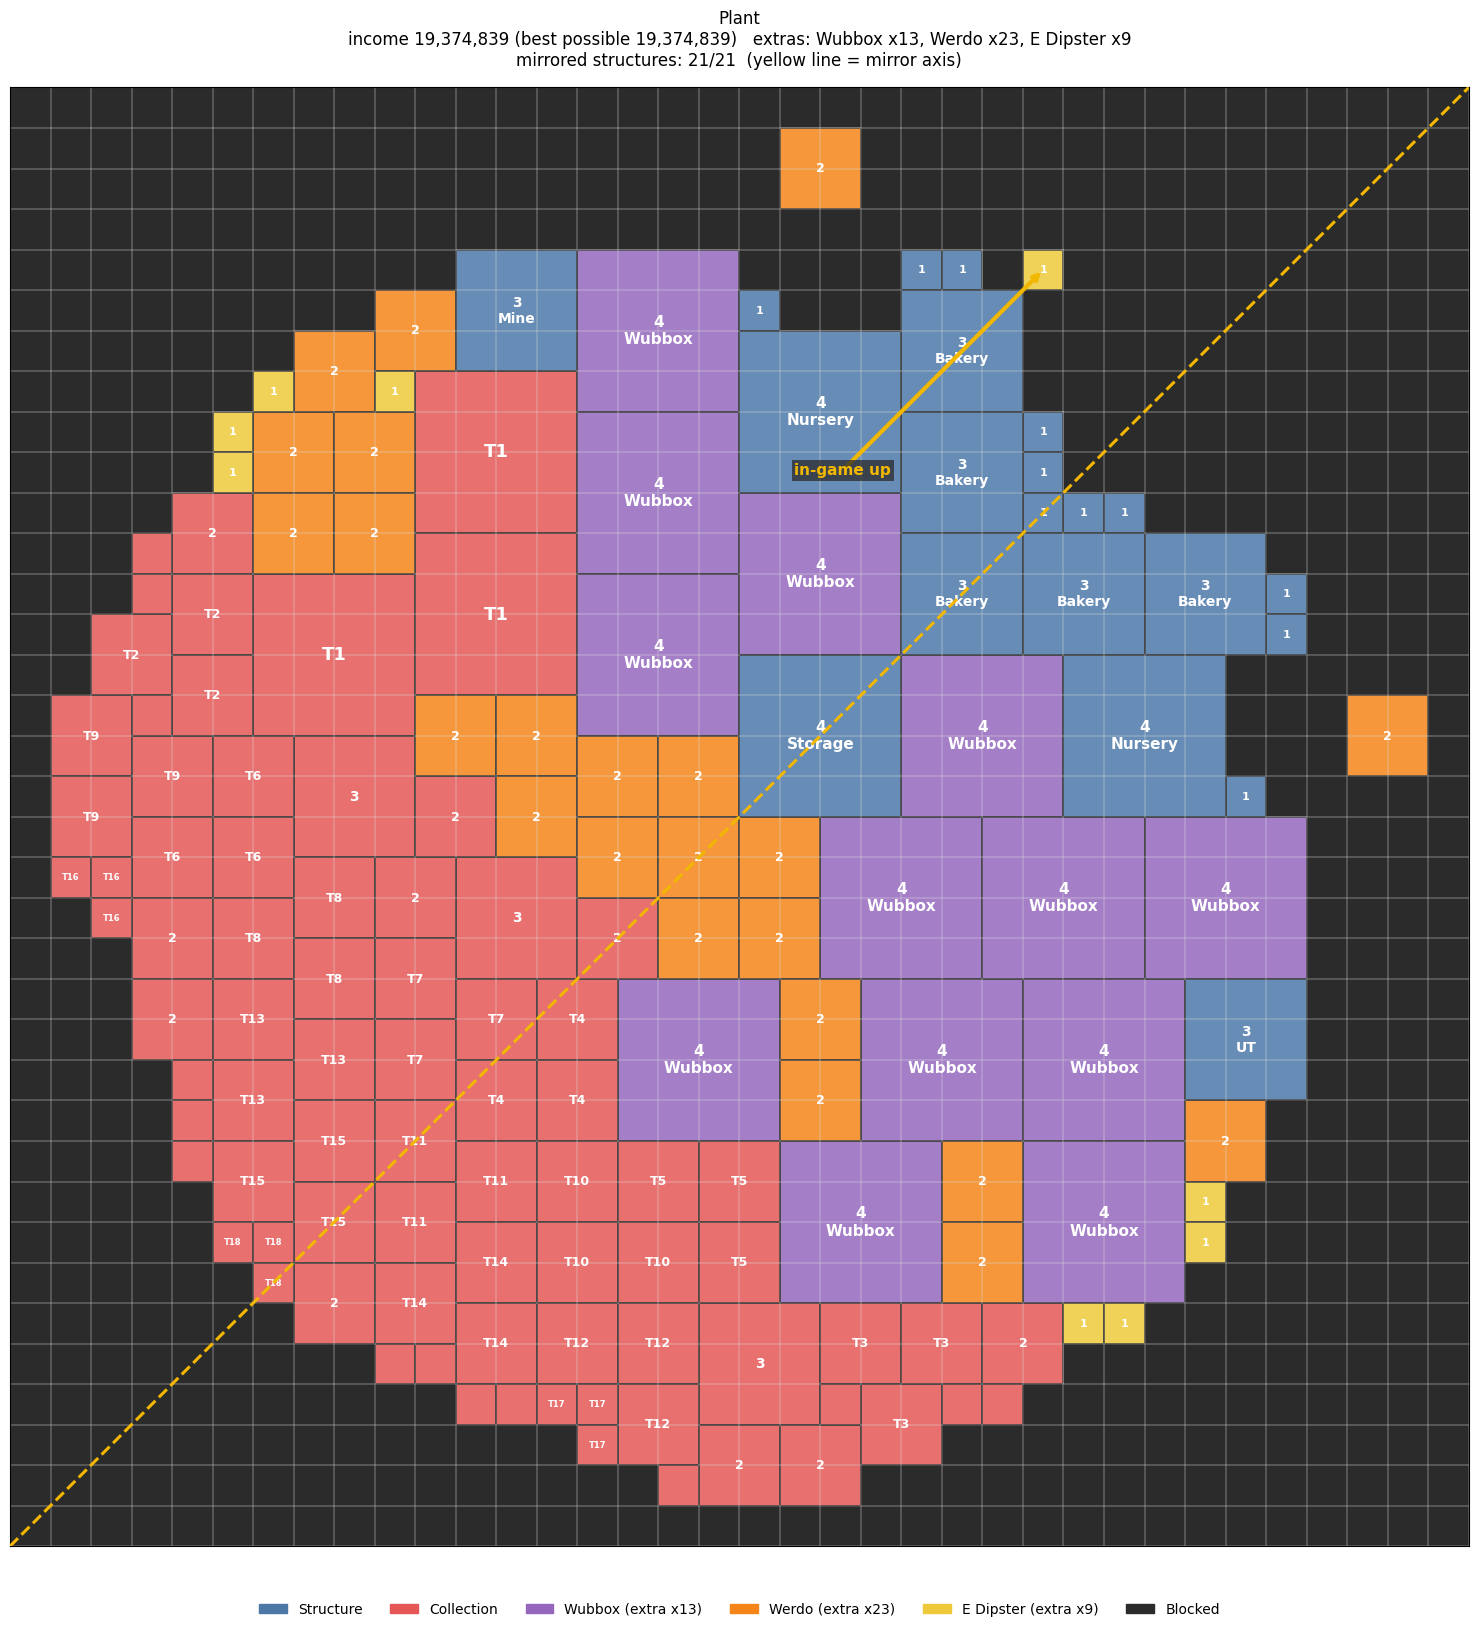

Saved: Plant.xlsx


In [4]:
# ── Run one island ───────────────────────────────────────────────────────────
layout = msm.solve(msm.Island.from_dict(ISLAND, ISLANDS[ISLAND]), **OPTIONS)
print(msm.report(layout))
msm.draw(layout)
print("Saved:", msm.export_excel(layout))

# Run all islands

In [ ]:
# ── Run all islands ──────────────────────────────────────────────────────────
# Solves every island in ISLANDS, writes each one's Excel file and prints a table.
# An island that fails is reported and the rest still run.
results = msm.run_all(ISLANDS, parallel=PARALLEL, **OPTIONS)